# 05 — Fairness Evaluation
**Workforce Pulse · Phase 6 · Responsible AI**

**Design.** `Age`, `Gender` and `MaritalStatus` were **excluded from the model's features**. They are held in a separate
audit view and joined to the model's predictions **only here**, after scoring.

**Questions**
1. Does the model flag groups at different rates, and do those differences track real differences in attrition?
2. Does it **miss** leavers (false negatives) or **wrongly flag** stayers (false positives) more in some groups?
3. Are probabilities equally well calibrated across groups?
4. Can the model's features act as **proxies** for protected attributes?

**Data.** Out-of-fold predictions for all 1,470 employees (each scored by a model that never saw them) are used instead
of the 368-row test set: subgroup estimates would otherwise rest on a handful of leavers. Rates have 95 % Wilson CIs.

> Ethical boundary: this model is a research / decision-support prototype. It must never autonomously rank employees
> for dismissal, promotion, pay or any other employment decision.

## 0. Setup

In [1]:
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
DATA = PROJECT_ROOT / "data"
FIG_DIR = PROJECT_ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore", category=FutureWarning)

import json
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from src.evaluation import group_fairness
from src.features import MODEL_NUMERIC, MODEL_CATEGORICAL

cfg = json.loads((PROJECT_ROOT / "models" / "model_config.json").read_text())
THRESHOLD = cfg["threshold"]
pred = pd.read_csv(DATA / "predictions" / "employee_attrition_predictions.csv")
audit = pd.read_csv(DATA / "processed" / "hr_featured.csv")[["EmployeeNumber", "Age", "AgeBand", "Gender", "MaritalStatus"]]
d = pred.merge(audit, on="EmployeeNumber", validate="one_to_one")
AGE_ORDER = ["Under 25", "25-34", "35-44", "45-54", "55+"]
print("Model:", cfg["selected_model"], "| threshold:", THRESHOLD, "| rows:", len(d))

Model: LogisticRegression | threshold: 0.14 | rows: 1470


## 1. Group-level error profile
| Metric | Fairness question |
|---|---|
| base_rate | How often did this group actually leave? (context for everything else) |
| flag_rate | How often does the model flag this group? (demographic parity) |
| recall_TPR | Of actual leavers, how many are caught? (equal opportunity) |
| FPR | Of stayers, how many are wrongly flagged? |
| FNR | Of leavers, how many are missed? |
| precision | Of flagged employees, how many actually left? (predictive parity) |

In [2]:
def audit_table(col, order=None):
    t = group_fairness(d.AttritionFlag, d.PredictedProbability, d[col], THRESHOLD).set_index("group")
    if order: t = t.reindex(order)
    fmt = lambda ci: f"[{ci[0]:.2f}, {ci[1]:.2f}]"
    for c in ["flag_rate_CI", "recall_CI", "FPR_CI"]:
        t[c] = t[c].map(fmt)
    return t

results = {"Gender": audit_table("Gender"), "MaritalStatus": audit_table("MaritalStatus", ["Single", "Married", "Divorced"]),
           "AgeBand": audit_table("AgeBand", AGE_ORDER)}
for k, t in results.items():
    print(f"\n=== {k} ===")
    display(t.round(3))


=== Gender ===


,n,actual_leavers,base_rate,mean_predicted_risk,flag_rate,recall_TPR,FPR,FNR,precision,flag_rate_CI,recall_CI,FPR_CI
group,,,,,,,,,,,,
Female,588,87,0.148,0.171,0.403,0.828,0.329,0.172,0.304,"[0.36, 0.44]","[0.73, 0.89]","[0.29, 0.37]"
Male,882,150,0.170,0.160,0.374,0.767,0.294,0.233,0.348,"[0.34, 0.41]","[0.69, 0.83]","[0.26, 0.33]"



=== MaritalStatus ===


,n,actual_leavers,base_rate,mean_predicted_risk,flag_rate,recall_TPR,FPR,FNR,precision,flag_rate_CI,recall_CI,FPR_CI
group,,,,,,,,,,,,
Single,470,120,0.255,0.219,0.494,0.850,0.371,0.150,0.440,"[0.45, 0.54]","[0.78, 0.90]","[0.32, 0.42]"
Married,673,84,0.125,0.145,0.363,0.667,0.319,0.333,0.230,"[0.33, 0.40]","[0.56, 0.76]","[0.28, 0.36]"
Divorced,327,33,0.101,0.126,0.278,0.879,0.211,0.121,0.319,"[0.23, 0.33]","[0.73, 0.95]","[0.17, 0.26]"



=== AgeBand ===


,n,actual_leavers,base_rate,mean_predicted_risk,flag_rate,recall_TPR,FPR,FNR,precision,flag_rate_CI,recall_CI,FPR_CI
group,,,,,,,,,,,,
Under 25,97,38,0.392,0.292,0.660,0.895,0.508,0.105,0.531,"[0.56, 0.75]","[0.76, 0.96]","[0.38, 0.63]"
25-34,554,112,0.202,0.184,0.413,0.848,0.303,0.152,0.415,"[0.37, 0.45]","[0.77, 0.90]","[0.26, 0.35]"
35-44,505,51,0.101,0.148,0.370,0.745,0.328,0.255,0.203,"[0.33, 0.41]","[0.61, 0.84]","[0.29, 0.37]"
45-54,245,25,0.102,0.117,0.282,0.600,0.245,0.400,0.217,"[0.23, 0.34]","[0.41, 0.77]","[0.19, 0.31]"
55+,69,11,0.159,0.112,0.261,0.455,0.224,0.545,0.278,"[0.17, 0.38]","[0.21, 0.72]","[0.14, 0.35]"


## 2. Disparity summary
Relative to the largest group in each attribute (reference):
- **Flag-rate ratio:** group flag rate / reference flag rate. Below 0.8 or above 1.25 is used as a *screening* signal,
  borrowed from the four-fifths heuristic. It is not a legal test here.
- **Base-rate ratio:** the same ratio for **actual** attrition. If the flag-rate ratio ≈ base-rate ratio, the model
  mirrors real outcome differences rather than adding new ones.
- **TPR gap / FPR gap:** percentage-point differences in recall and false positive rate.

In [3]:
rows = []
for attr, t in results.items():
    ref = t["n"].idxmax()
    for g, r in t.iterrows():
        rows.append({"attribute": attr, "group": g, "reference": ref, "n": r.n, "leavers": r.actual_leavers,
                     "base_rate_ratio": r.base_rate / t.loc[ref, "base_rate"],
                     "flag_rate_ratio": r.flag_rate / t.loc[ref, "flag_rate"],
                     "TPR_gap_pp": 100 * (r.recall_TPR - t.loc[ref, "recall_TPR"]),
                     "FPR_gap_pp": 100 * (r.FPR - t.loc[ref, "FPR"]),
                     "calibration_gap_pp": 100 * (r.mean_predicted_risk - r.base_rate)})
disp = pd.DataFrame(rows)
disp["parity_screen"] = np.where(disp.flag_rate_ratio.between(0.8, 1.25), "within", "OUTSIDE")
disp["small_group"] = disp.leavers < 30
disp.to_csv(PROJECT_ROOT / "reports" / "fairness_disparities.csv", index=False)
disp.round(3)

,attribute,group,reference,n,leavers,base_rate_ratio,flag_rate_ratio,TPR_gap_pp,FPR_gap_pp,calibration_gap_pp,parity_screen,small_group
0,Gender,Female,Male,588,87,0.870,1.077,6.092,3.563,2.316,within,False
1,Gender,Male,Male,882,150,1.000,1.000,0.000,0.000,-1.010,within,False
2,MaritalStatus,Single,Married,470,120,2.046,1.361,18.333,5.224,-3.612,OUTSIDE,False
3,MaritalStatus,Married,Married,673,84,1.000,1.000,0.000,0.000,2.016,within,False
4,MaritalStatus,Divorced,Married,327,33,0.809,0.768,21.212,-10.830,2.484,OUTSIDE,False
5,AgeBand,Under 25,25-34,97,38,1.938,1.596,4.652,20.531,-9.954,OUTSIDE,False
6,AgeBand,25-34,25-34,554,112,1.000,1.000,0.000,0.000,-1.774,within,False
7,AgeBand,35-44,25-34,505,51,0.500,0.896,-10.312,2.503,4.689,within,False
8,AgeBand,45-54,25-34,245,25,0.505,0.681,-24.821,-5.771,1.536,OUTSIDE,True
9,AgeBand,55+,25-34,69,11,0.789,0.631,-39.367,-7.903,-4.696,OUTSIDE,True


## 3. Visual audit

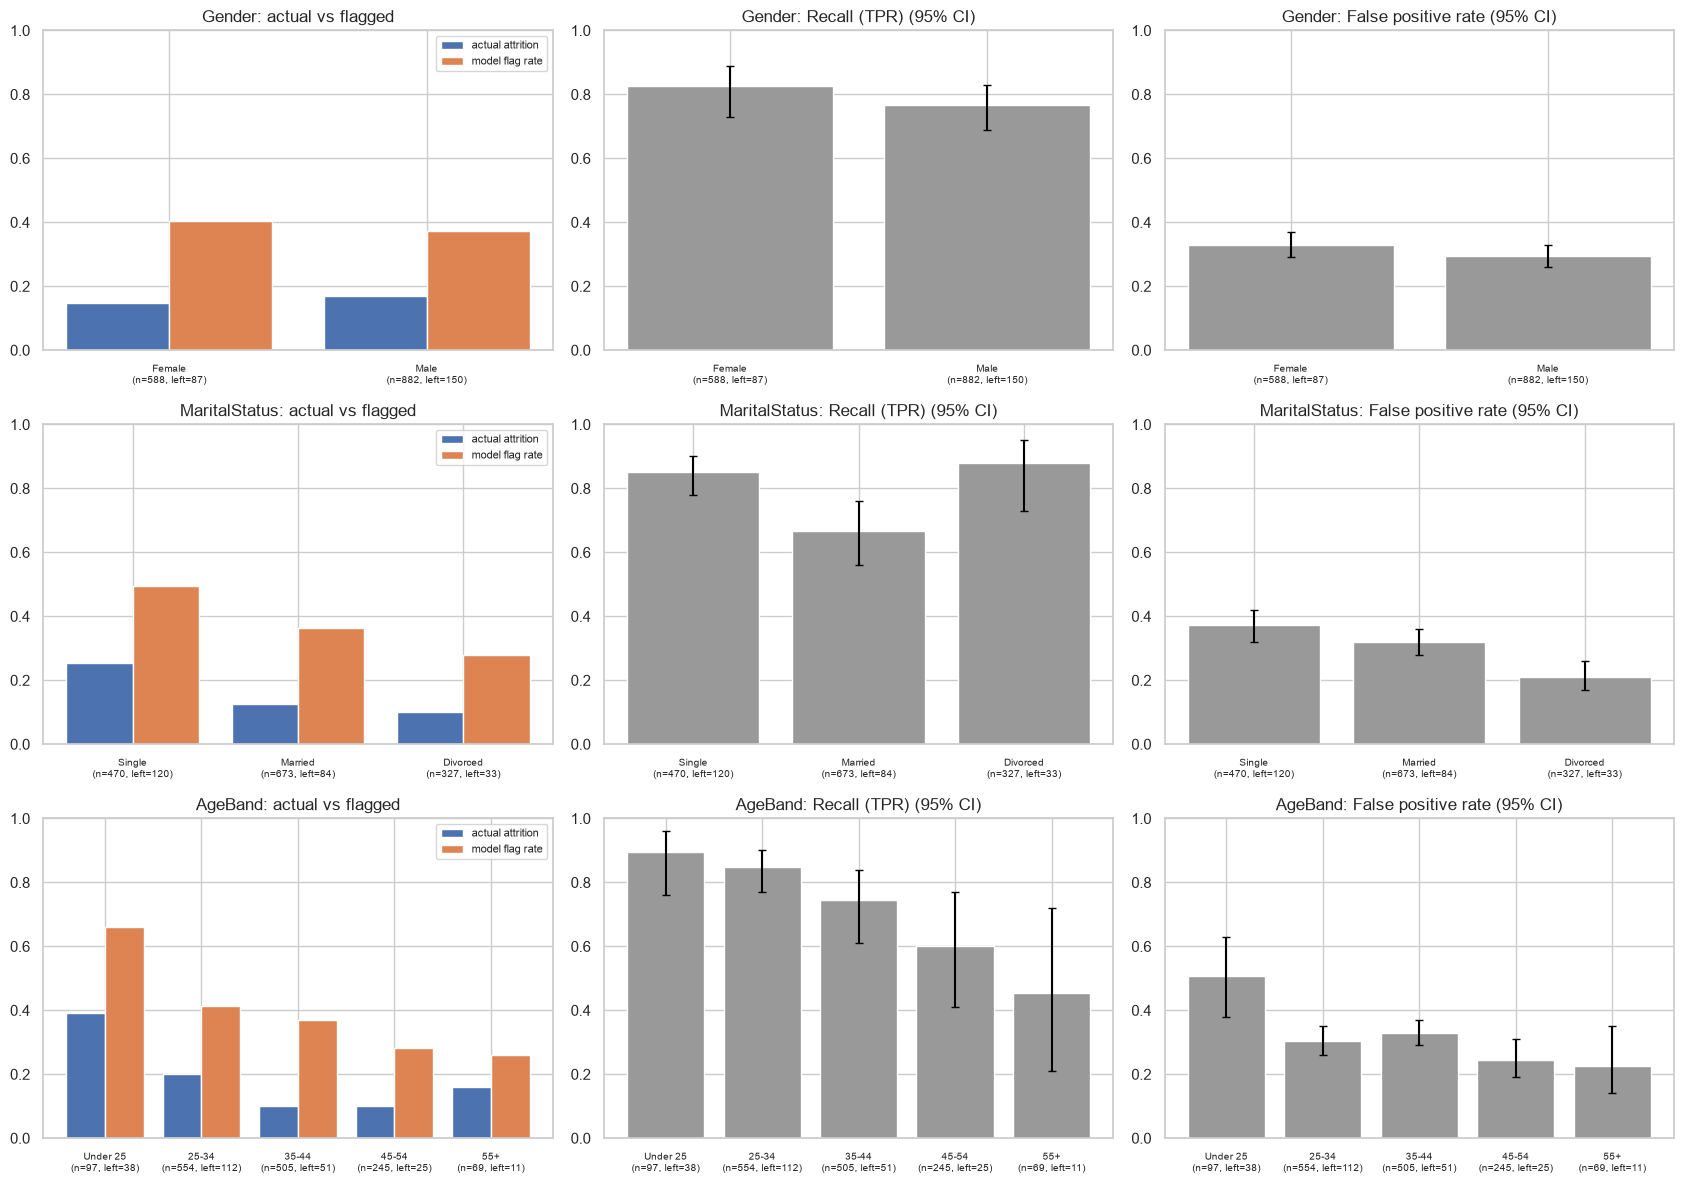

In [4]:
fig, axes = plt.subplots(3, 3, figsize=(17, 12))
for row, (attr, t) in enumerate(results.items()):
    x = np.arange(len(t)); labels = [f"{g}\n(n={n}, left={l})" for g, n, l in zip(t.index, t.n, t.actual_leavers)]
    axes[row, 0].bar(x - 0.2, t.base_rate, 0.4, label="actual attrition", color="#4C72B0")
    axes[row, 0].bar(x + 0.2, t.flag_rate, 0.4, label="model flag rate", color="#DD8452")
    axes[row, 0].set_title(f"{attr}: actual vs flagged"); axes[row, 0].legend(fontsize=8)
    for ax, m, ttl in [(axes[row, 1], "recall_TPR", "Recall (TPR)"), (axes[row, 2], "FPR", "False positive rate")]:
        lo = [float(s.strip("[]").split(",")[0]) for s in t[m.split("_")[0] + "_CI" if m == "FPR" else "recall_CI"]]
        hi = [float(s.strip("[]").split(",")[1]) for s in t[m.split("_")[0] + "_CI" if m == "FPR" else "recall_CI"]]
        ax.bar(x, t[m], color="#999999")
        ax.errorbar(x, t[m], yerr=[t[m] - lo, np.array(hi) - t[m]], fmt="none", ecolor="black", capsize=3)
        ax.set_title(f"{attr}: {ttl} (95% CI)")
    for ax in axes[row]:
        ax.set_xticks(x, labels, fontsize=7.5); ax.set_ylim(0, 1)
plt.tight_layout(); plt.savefig(FIG_DIR / "19_fairness_audit.png", dpi=150); plt.show()

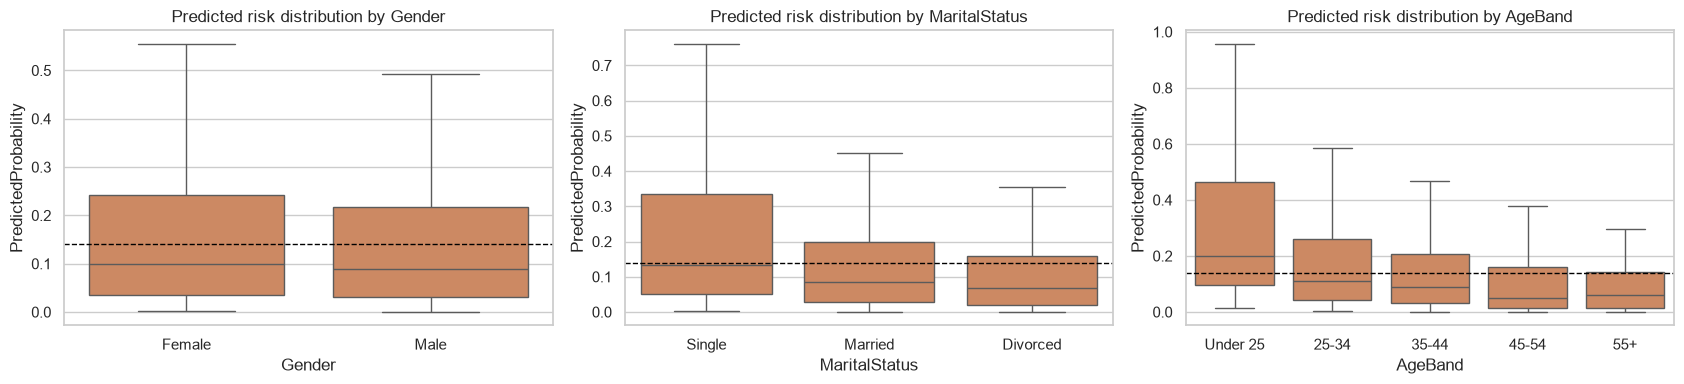

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, (col, order) in zip(axes, [("Gender", None), ("MaritalStatus", ["Single", "Married", "Divorced"]), ("AgeBand", AGE_ORDER)]):
    sns.boxplot(data=d, x=col, y="PredictedProbability", order=order, ax=ax, color="#DD8452", showfliers=False)
    ax.axhline(THRESHOLD, ls="--", color="black", lw=1); ax.set_title(f"Predicted risk distribution by {col}")
plt.tight_layout(); plt.savefig(FIG_DIR / "20_risk_distribution_by_group.png", dpi=150); plt.show()

## 4. Proxy analysis
If the model's **input features** can predict a protected attribute, excluding that attribute does not stop the model
from encoding it. We train a simple classifier: *model features → protected attribute*, and report cross-validated
ROC-AUC (0.5 = no information, 1.0 = perfect proxy). For Age we predict "age 35 or older".

In [6]:
feat = pd.read_csv(DATA / "processed" / "hr_featured.csv")
Xp = feat[MODEL_NUMERIC + MODEL_CATEGORICAL + ["SalaryRatioToLevel"]]
proxy_pipe = make_pipeline(
    ColumnTransformer([("num", StandardScaler(), MODEL_NUMERIC + ["SalaryRatioToLevel"]),
                       ("cat", OneHotEncoder(handle_unknown="ignore"), MODEL_CATEGORICAL)]),
    LogisticRegression(max_iter=3000))
targets = {"Gender = Female": feat.Gender == "Female", "MaritalStatus = Single": feat.MaritalStatus == "Single",
           "Age >= 35": feat.Age >= 35}
cvp = StratifiedKFold(5, shuffle=True, random_state=42)
proxy = pd.DataFrame({k: {"positives": int(v.sum()),
                          "cv_roc_auc": cross_val_score(proxy_pipe, Xp, v.astype(int), cv=cvp, scoring="roc_auc").mean()}
                      for k, v in targets.items()}).T
proxy.round(3)

,positives,cv_roc_auc
Gender = Female,588.0,0.504
MaritalStatus = Single,470.0,0.934
Age >= 35,819.0,0.828


In [7]:
# Which single features carry the most protected-attribute information?
def single_feature_auc(target):
    out = {}
    for c in MODEL_NUMERIC + ["SalaryRatioToLevel"]:
        from sklearn.metrics import roc_auc_score
        a = roc_auc_score(target.astype(int), feat[c]); out[c] = max(a, 1 - a)
    return pd.Series(out).sort_values(ascending=False).head(4).round(3)
pd.DataFrame({k: single_feature_auc(v).reset_index().apply(lambda r: f"{r['index']} ({r[0]})", axis=1)
              for k, v in targets.items()})

,Gender = Female,MaritalStatus = Single,Age >= 35
0,TotalWorkingYears (0.529),StockOptionLevel (0.92),TotalWorkingYears (0.817)
1,JobLevel (0.528),TotalWorkingYears (0.562),JobLevel (0.72)
2,MonthlyIncome (0.526),MonthlyIncome (0.557),MonthlyIncome (0.72)
3,YearsAtCompany (0.525),JobLevel (0.553),NumCompaniesWorked (0.669)


## 5. Conditional check: is the MaritalStatus / Age disparity explained by legitimate features?
Within the same overtime status and tenure band, does the model still flag Single (or younger) employees more?
If the gap shrinks a lot, the disparity mostly runs through work-related features. If it persists, the model
is encoding the protected attribute through proxies.

In [8]:
d2 = d.merge(feat[["EmployeeNumber", "OverTime", "TenureBand"]], on="EmployeeNumber")
d2["Young"] = np.where(d2.Age < 30, "Under 30", "30+")
def strat(attr):
    g = d2.groupby(["OverTime", "TenureBand", attr]).agg(n=("PredictedClass", "size"), flag_rate=("PredictedClass", "mean"),
                                                       base_rate=("AttritionFlag", "mean")).reset_index()
    return g[g.n >= 20].pivot_table(index=["OverTime", "TenureBand"], columns=attr, values=["flag_rate", "base_rate"]).round(3)
display(strat("MaritalStatus"))
strat("Young")

base_rate                flag_rate               
MaritalStatus          Divorced Married Single  Divorced Married Single
OverTime TenureBand                                                    
No       Early (3-5y)     0.075   0.034  0.149     0.209   0.308  0.436
         Long (11y+)      0.027   0.109  0.038     0.027   0.130  0.173
         Mid (6-10y)      0.026   0.074  0.106     0.039   0.176  0.288
         New (0-2y)       0.125   0.149  0.315     0.438   0.465  0.528
Yes      Early (3-5y)     0.267   0.218  0.381     0.733   0.636  0.857
         Long (11y+)      0.000   0.036    NaN     0.350   0.357    NaN
         Mid (6-10y)      0.143   0.210  0.467     0.393   0.548  0.733
         New (0-2y)       0.333   0.415  0.690     0.571   0.854  0.881

base_rate          flag_rate         
Young                       30+ Under 30       30+ Under 30
OverTime TenureBand                                        
No       Early (3-5y)     0.081    0.070     0.285    0.430
         Long (11y+)      0.067      NaN     0.124      NaN
         Mid (6-10y)      0.071    0.083     0.187    0.150
         New (0-2y)       0.129    0.349     0.419    0.602
Yes      Early (3-5y)     0.250    0.387     0.688    0.871
         Long (11y+)      0.108      NaN     0.415      NaN
         Mid (6-10y)      0.215    0.407     0.505    0.741
         New (0-2y)       0.382    0.750     0.735    0.944

## 6. Mitigation experiment: remove the strongest proxy
In this dataset **every Single employee has StockOptionLevel = 0** (see crosstab), so StockOptionLevel is close to a
direct encoding of marital status. We refit the selected model configuration **without StockOptionLevel**, using the
same out-of-fold procedure and threshold, and compare: (a) predictive performance, (b) marital-status disparities.
This is an *experiment*, not an automatic fix: removing a proxy can lower accuracy without removing the disparity.

In [9]:
display(pd.crosstab(feat.MaritalStatus, feat.StockOptionLevel))
import os; os.environ["PYTHONPATH"] = str(PROJECT_ROOT)
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.metrics import average_precision_score, roc_auc_score
from src.features import PeerSalaryRatio

def oof_scores(numeric):
    pipe = Pipeline([("peer", PeerSalaryRatio()),
                     ("prep", ColumnTransformer([("num", StandardScaler(), numeric),
                                                 ("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary"), MODEL_CATEGORICAL)])),
                     ("model", LogisticRegression(max_iter=5000, C=cfg["hyperparameters"]["C"],
                                                  class_weight=cfg["hyperparameters"]["class_weight"]))])
    Xm = feat[MODEL_NUMERIC + MODEL_CATEGORICAL]
    return cross_val_predict(CalibratedClassifierCV(pipe, method="sigmoid", cv=5), Xm, feat.AttritionFlag,
                             cv=StratifiedKFold(5, shuffle=True, random_state=42), method="predict_proba", n_jobs=-1)[:, 1]

base_numeric = cfg["model_numeric_features"]
variants = {"current model": d.set_index("EmployeeNumber").loc[feat.EmployeeNumber, "PredictedProbability"].to_numpy(),
            "without StockOptionLevel": oof_scores([c for c in base_numeric if c != "StockOptionLevel"])}
rows = []
for name, p in variants.items():
    flag = p >= THRESHOLD
    r = {"variant": name, "PR_AUC": average_precision_score(feat.AttritionFlag, p), "ROC_AUC": roc_auc_score(feat.AttritionFlag, p)}
    for g in ["Single", "Married", "Divorced"]:
        m = feat.MaritalStatus == g
        r[f"flag_{g}"] = flag[m].mean()
        r[f"recall_{g}"] = flag[m & (feat.AttritionFlag == 1)].mean()
    r["flag_ratio_Single/Married"] = r["flag_Single"] / r["flag_Married"]
    rows.append(r)
mitigation = pd.DataFrame(rows).set_index("variant").T
mitigation.round(3)

StockOptionLevel,0,1,2,3
MaritalStatus,,,,
Divorced,8,195,75,49
Married,153,401,83,36
Single,470,0,0,0


variant,current model,without StockOptionLevel
PR_AUC,0.625,0.590
ROC_AUC,0.830,0.816
flag_Single,0.494,0.394
recall_Single,0.850,0.800
flag_Married,0.363,0.391
recall_Married,0.667,0.690
flag_Divorced,0.278,0.391
recall_Divorced,0.879,0.879
flag_ratio_Single/Married,1.361,1.007


Interpretation and recommendations: `reports/fairness_report.md`.